# 05. Evaluasi tracker dengan ground truth PT SRP

Penilaian yang paling bisa dipertanggungjawabkan: tracker dibandingkan dengan **label ID orang dari manusia** di klip CCTV PT SRP. Notebook 02 hanya membandingkan dengan tracker referensi, dan notebook 03 memakai MOT17 yang bukan gudang.

| Bagian | Isi |
|---|---|
| 1 | Baca label dan **cek dulu**: jumlah frame, ukuran, area diabaikan, box di atas video |
| 2 | Deteksi orang di setiap frame, per detektor (sekali, disimpan), lalu cek label pas dengan video |
| 3 | Nilai semua tracker di beberapa FPS: HOTA, IDF1, ID switch, MOTA |
| 4 | **Pipeline**: semua run di `runs/` dinilai dengan label yang sama, termasuk pipeline dengan Lite terpasang (`scripts/run_pipeline_lite.py`) |
| 5 | Detektor sempurna: tracker diberi box label, untuk memisahkan kesalahan tracker dari kesalahan detektor |
| 6 | **Tolok ukur detektor**: recall, presisi, AP50, dan sebab setiap orang yang terlewat atau box yang salah. Definisinya tetap, jadi detektor baru bisa langsung dibandingkan |
| 7 | Per klip, dan ketahanan terhadap video blur dan re-encode |
| 8 | Validasi silang ambang Lite |
| 9 | Video perbandingan dengan tanda ID switch |
| 10 | Simpan hasil |

**Data.** Bawaannya membaca folder `~/PPE - PT SRP/ground truth/`:
```
ground truth/
  <klip>_15fps.mp4                 video 15 FPS
  frozen/<klip>/gt.jsonl, meta.json   label beku: satu baris per orang per frame, area diabaikan, status helm/vest
  runs/<run>/<klip>/observations.jsonl   output pipeline yang sudah dijalankan (hen-detect-ppe, srp-ppe-be)
```
Folder lain berisi export CVAT ("CVAT for video 1.1" `annotations.xml`, atau "MOT 1.1" `gt/gt.txt`) juga bisa dipakai, cukup ganti `GT_DIR`.

**Aturan penilaian** (mengikuti MOTChallenge):
- Box orang yang ditandai `occluded` (tertutup sebagian) tetap **dinilai** (`OCCLUDED = "nilai"`). Di beberapa klip hampir semua orang ditandai tertutup sebagian, jadi mengabaikannya akan menghapus klip itu.
- Box `small` (lebih kecil dari batas tinggi di meta) dan **area diabaikan** di meta tidak dinilai: box tracker di sana tidak dihitung benar maupun salah.
- Klip yang hanya dilabeli di sebagian frame (misalnya v10, setiap 5 frame) hanya dinilai di frame berlabel.
- Label yang bergeser dari video (misalnya terlambat 2 frame) digeser otomatis di bagian 2 (`GESER_LABEL_OTOMATIS`).

Hasil tersimpan di `experiments/05_ground_truth/<waktu>/`.

In [1]:
# Cek Python yang dipakai notebook. Harus .venv milik repo ini.
import sys, importlib.util
print("Python:", sys.executable)
missing = [m for m in ('numpy', 'scipy', 'pandas', 'matplotlib', 'cv2', 'onnxruntime', 'ultralytics') if importlib.util.find_spec(m) is None]
if ".venv" not in sys.executable or missing:
    raise RuntimeError(
        "Notebook belum memakai .venv proyek" + (f" (paket tidak ada: {', '.join(missing)})" if missing else "") + ".\n"
        "Jalankan `uv sync` di folder repo, lalu di VS Code: klik nama kernel di kanan atas > Select Another Kernel > "
        "Python Environments > .venv (object-tracking), atau Enter interpreter path: "
        "~/Documents/GitHub/object-tracking/.venv/bin/python"
    )
print("ok, semua paket ada")

Python: /Users/rdrusdiati/Documents/GitHub/object-tracking/.venv/bin/python
ok, semua paket ada


## 0. Pengaturan

In [2]:
import os, sys, json, time, platform, warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=UserWarning)
REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(REPO / "src"))

from object_tracking import ground_truth as gtm, mot17, mot17_video
from object_tracking.zoo import PRESETS, LITE_DEFAULT, load_tuned

try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = None

# ===================== ubah di sini =====================
GT_ROOT    = Path(os.environ.get("OT_GT_ROOT", Path.home() / "PPE - PT SRP" / "ground truth"))
GT_DIR     = GT_ROOT / "frozen"          # satu subfolder per klip
VIDEO_DIRS = [GT_ROOT]                   # tempat video <klip>_15fps.mp4
RUNS_DIR   = GT_ROOT / "runs"            # output pipeline lain (boleh tidak ada)
DETECTORS  = {                           # nama: file model. Detektor pertama dipakai untuk bagian 5 sampai 8
    "dfine-n-960x540-stride-8": REPO / "models" / "dfine-n-960x540-stride-8.onnx",
    "dfine-n-stg2-960 (pipeline sekarang)": REPO / "models" / "dfine-n-stg2-960.onnx",
}
OCCLUDED   = "nilai"                     # orang tertutup sebagian: "nilai" atau "abaikan"
SMALL      = "abaikan"                   # box kecil (di bawah min_h_px di meta): "abaikan" atau "nilai"
FPS_LIST   = [None, 5, 3, 2]             # None = FPS asli video (15). 3 = FPS evaluasi pipeline
MAIN_FPS   = 3
INCLUDE_VARIANTS = True                  # nilai juga klip _blur dan _reenc (bagian 6, ketahanan)
MAX_SEC    = None                        # potong durasi tiap klip (detik). None = seluruh klip
GESER_LABEL_OTOMATIS = True              # label yang tidak sejajar dengan video digeser (bagian 2)
KELOMPOK   = {                           # kelompok klip untuk laporan. Klip "bocor" punya frame di data training
    "v03_momen_026_0000-0103s": "klien bersih", "v10_momen_004_0000-0080s": "klien bersih",
    "v15_momen_015_0000-0091s": "klien bocor", "v18_momen_002_0000-0035s": "klien bocor",
}
QUICK      = os.environ.get("OT_QUICK", "0") == "1"
# ========================================================
if QUICK:
    FPS_LIST, MAX_SEC, INCLUDE_VARIANTS = [None, 3], MAX_SEC or 20, False

RUN_ID = datetime.now().strftime("%Y%m%d_%H%M") + ("_quick" if QUICK else "")
OUT = REPO / "experiments" / "05_ground_truth" / RUN_ID
FIG = OUT / "figures"
CACHE = REPO / "outputs" / "cache" / "ground_truth"
for p in (OUT, FIG, CACHE):
    p.mkdir(parents=True, exist_ok=True)
RESULTS = {"run_id": RUN_ID, "quick": QUICK, "occluded": OCCLUDED, "small": SMALL,
           "detectors": {k: v.name for k, v in DETECTORS.items()},
           "host": {"platform": platform.platform(), "machine": platform.machine()}}

def save_results():
    (OUT / "results.json").write_text(json.dumps(RESULTS, indent=2, default=float, ensure_ascii=False))

def savefig(name):
    plt.savefig(FIG / f"{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

def prog(x, **kw):
    return tqdm(x, leave=False, **kw) if tqdm else x

COLS = ["HOTA", "IDF1", "MOTA", "AssA", "DetA", "IDSW", "IDs", "GT_IDs"]
FMT = {"HOTA": "{:.3f}", "IDF1": "{:.3f}", "MOTA": "{:.3f}", "AssA": "{:.3f}", "DetA": "{:.3f}"}
def show(df, cols=COLS):
    return df[[c for c in cols if c in df.columns]].style.format(FMT).background_gradient(
        subset=[c for c in ("HOTA", "IDF1") if c in df.columns], cmap="Greens")

def fps_label(f):
    return "asli" if f in (None, "asli") else f"{f:g}"

def kelompok(name):
    base = name.rsplit("_", 1)[0] if name.endswith(("_blur", "_reenc")) else name
    return KELOMPOK.get(base, "eksternal" if base.startswith("sub_") else "klien")

for name, p in [("label", GT_DIR), ("runs", RUNS_DIR)] + [(f"detektor {k}", v) for k, v in DETECTORS.items()]:
    print(f"{'ok' if p.exists() else 'TIDAK ADA':9s} {name:40s} {p}")
DETECTORS = {k: v for k, v in DETECTORS.items() if v.exists()}
print("hasil:", OUT)

ok        label                                    /Users/rdrusdiati/PPE - PT SRP/ground truth/frozen
ok        runs                                     /Users/rdrusdiati/PPE - PT SRP/ground truth/runs
ok        detektor dfine-n-960x540-stride-8        /Users/rdrusdiati/Documents/GitHub/object-tracking/models/dfine-n-960x540-stride-8.onnx
ok        detektor dfine-n-stg2-960 (pipeline sekarang) /Users/rdrusdiati/Documents/GitHub/object-tracking/models/dfine-n-stg2-960.onnx
hasil: /Users/rdrusdiati/Documents/GitHub/object-tracking/experiments/05_ground_truth/20261112_1422


## 1. Baca label dan cek

Jangan lewati bagian ini. Label yang bergeser beberapa frame, ukuran video yang berbeda, atau satu orang yang diberi dua ID akan membuat semua tracker terlihat buruk, padahal yang salah labelnya.

In [3]:
ALL_CLIPS = [c for c in gtm.find_clips(GT_DIR, VIDEO_DIRS, variants=True)]
missing = [c.name for c in ALL_CLIPS if c.video is None]
ALL_CLIPS = [c for c in ALL_CLIPS if c.video is not None]
CLIPS = [c for c in ALL_CLIPS if not c.name.endswith(("_blur", "_reenc"))]
VARIANTS = [c for c in ALL_CLIPS if c.name.endswith(("_blur", "_reenc"))] if INCLUDE_VARIANTS else []
check_df = pd.DataFrame([gtm.check(c) for c in CLIPS]).set_index("klip")
display(check_df)
if missing:
    print("Video tidak ditemukan, klip dilewati:", missing)
print(f"{len(CLIPS)} klip utama, {len(VARIANTS)} klip varian (blur/re-encode)")
RESULTS["clips"] = check_df.reset_index().to_dict("records")
save_results()

,format,orang (ID),box,frame dilabeli,persen tertutup,persen kecil,area diabaikan,video,FPS video,frame video,durasi (detik),peringatan
klip,,,,,,,,,,,,
sub_0_te6_0000-0015s,frozen,9,1350,225,31.0,5.1,2,sub_0_te6_0000-0015s_15fps.mp4,15.0,225,15.0,-
sub_1_te8_0000-0012s,frozen,7,954,169,53.0,4.2,3,sub_1_te8_0000-0012s_15fps.mp4,15.0,169,11.3,-
sub_5_te14_0000-0011s,frozen,7,565,155,0.0,13.1,3,sub_5_te14_0000-0011s_15fps.mp4,15.0,155,10.3,-
sub_5_te5_0000-0014s,frozen,3,597,209,8.9,10.2,1,sub_5_te5_0000-0014s_15fps.mp4,15.0,209,13.9,-
sub_7_te6_0000-0012s,frozen,3,354,180,62.1,0.0,3,sub_7_te6_0000-0012s_15fps.mp4,15.0,180,12.0,-
v03_momen_026_0000-0103s,frozen,1,1480,1541,100.0,0.0,0,v03_momen_026_0000-0103s_15fps.mp4,15.0,1541,102.7,-
v10_momen_004_0000-0080s,frozen,15,516,218,33.9,0.0,1,v10_momen_004_0000-0080s_15fps.mp4,15.0,1200,80.0,label hanya di 218 frame (tidak setiap frame):...
v15_momen_015_0000-0091s,frozen,3,3580,1361,20.9,0.0,1,v15_momen_015_0000-0091s_15fps.mp4,15.0,1361,90.7,-
v18_momen_002_0000-0035s,frozen,5,1840,516,29.7,0.0,0,v18_momen_002_0000-0035s_15fps.mp4,15.0,516,34.4,meta: shift_frames = 2 (cek pergeseran label v...


9 klip utama, 10 klip varian (blur/re-encode)


Box label di atas video. Warna = ID label, **T** = tertutup sebagian, **K** = kecil (tidak dinilai), kotak abu-abu = area diabaikan.

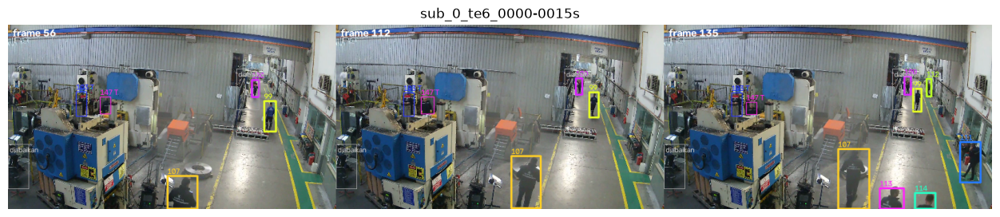

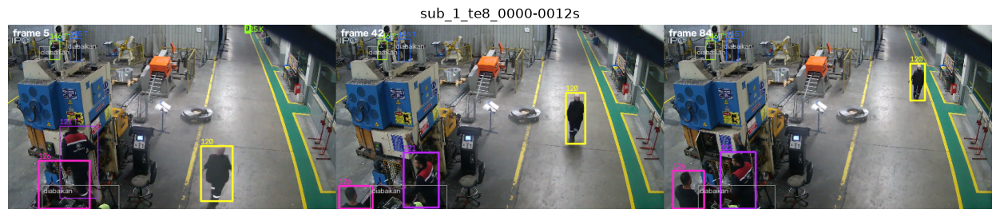

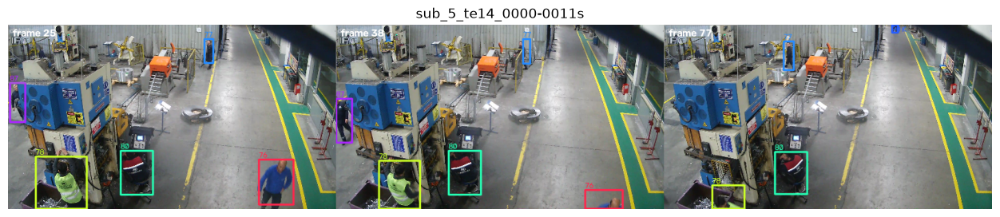

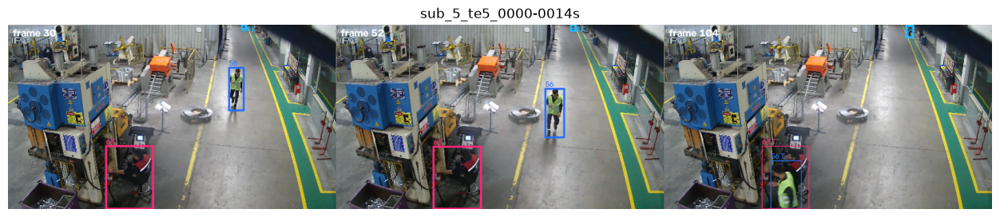

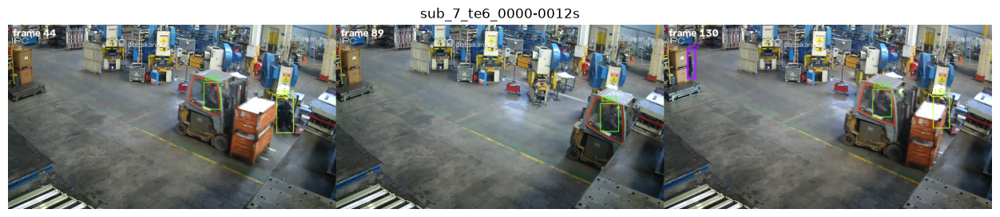

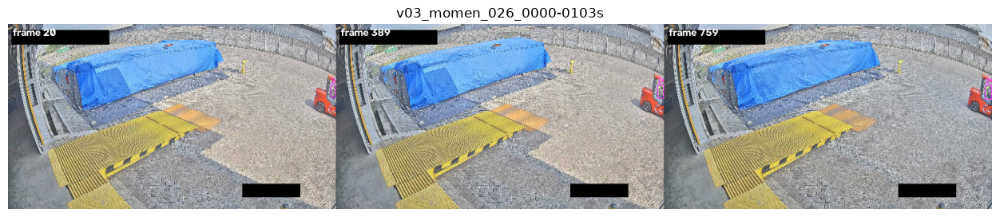

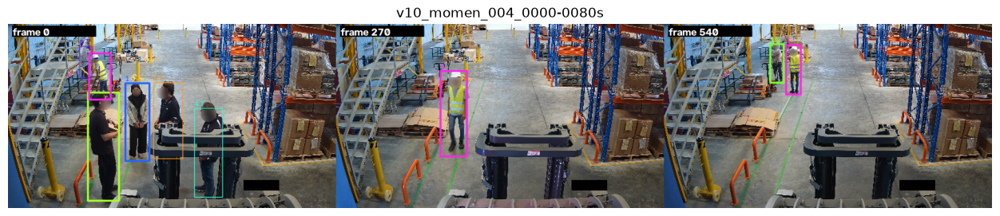

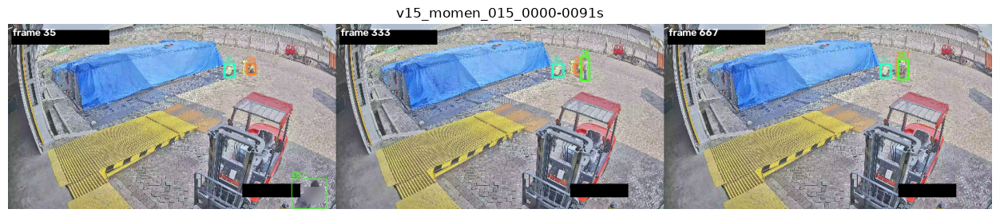

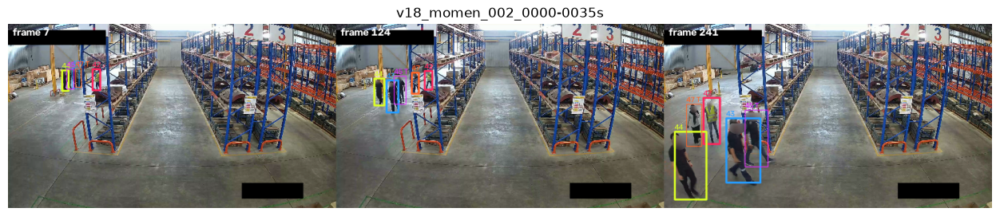

In [4]:
for c in CLIPS:
    img = gtm.overlay(c, n=3, width=560)
    plt.figure(figsize=(16, 16 * img.shape[0] / img.shape[1]))
    plt.imshow(img); plt.axis("off"); plt.title(c.name)
    savefig(f"label_{c.name}")

## 2. Deteksi orang di setiap frame

Setiap detektor dijalankan sekali di setiap frame video, lalu disimpan di `outputs/cache/ground_truth/`. Dari satu cache, semua FPS proses bisa dinilai dengan melompati frame. Klip 4K (v10) dan 2,7K paling lama: sekitar 5 sampai 10 menit per detektor untuk semua klip di Mac M5.

In [5]:
from object_tracking.detector import OnnxDFineDetector

def load_detector(path):
    for rt in ("coreml", "cpu"):
        try:
            return OnnxDFineDetector(path, runtime=rt, resize="area")
        except Exception as e:
            print(f"runtime {rt} tidak bisa dipakai: {e}")

DETS = {}          # (detektor, klip) -> {frame: Nx5}
for dname, dpath in DETECTORS.items():
    det = None
    for c in CLIPS + VARIANTS:
        if c in VARIANTS and dname != next(iter(DETECTORS)):
            continue                                   # varian hanya dengan detektor utama
        cp = CACHE / f"{c.name}_{dpath.stem}_{MAX_SEC or 'semua'}s.npz"
        if not cp.exists() and det is None:
            det = load_detector(dpath)
            print("detektor:", dpath.name, "|", det.active_providers[0])
        t0 = time.time()
        DETS[(dname, c.name)] = gtm.detect_clip(det, c, cp, max_sec=MAX_SEC,
                                                progress=lambda it, total: prog(it, total=total, desc=c.name))
        if time.time() - t0 > 2:
            print(f"  {c.name}: {len(DETS[(dname, c.name)])} frame, {time.time() - t0:.0f} s")
print("cache siap:", len(DETS))

cache siap: 28


### Cek label pas dengan video
Box deteksi (skor 0,5 ke atas) di setiap frame dibandingkan dengan label, dengan label digeser -4 sampai +4 frame. Pergeseran dengan rata-rata IoU tertinggi adalah posisi label yang sebenarnya. Cara ini juga bisa untuk klip yang hanya dilabeli tiap 5 frame, karena deteksinya ada di semua frame.

- **+2** artinya label terlambat 2 frame: box di frame f sebenarnya menggambar frame f + 2. Ini terjadi kalau pre-label diambil dari replay 3 fps dengan ffmpeg (sampel jatuh di frame 5k + 2).
- Kalau `GESER_LABEL_OTOMATIS = True`, pergeseran terbaik bukan 0, semua detektor setuju, dan IoU naik minimal 0,02, label klip itu dan versi blur/re-encode-nya digeser, dan semua bagian di bawah memakai label yang sudah digeser.

In [6]:
MAIN_DET = next(iter(DETECTORS))
rows, LABEL_SHIFT = [], {}
for c in CLIPS:
    best, score = gtm.label_offset(c, DETS[(MAIN_DET, c.name)])
    gain = score.get(best, 0) - score.get(0, 0)
    # dipakai hanya kalau jelas: semua detektor setuju, dan IoU naik minimal 0,02
    agree = all(gtm.label_offset(c, DETS[(d, c.name)])[0] == best for d in DETECTORS)
    use = best if (GESER_LABEL_OTOMATIS and best != 0 and gain >= 0.02 and agree) else 0
    LABEL_SHIFT[c.name] = use
    rows.append({"klip": c.name, "pergeseran terbaik": best, **{f"IoU geser {k:+d}": round(v, 3) for k, v in score.items()},
                 "dipakai": use, "catatan": "ok" if best == 0 else ("label digeser" if use else "PERIKSA: label bergeser dari video")})
align = pd.DataFrame(rows).set_index("klip")
display(align)
shift_of = lambda c: LABEL_SHIFT.get(c.name.rsplit("_", 1)[0] if c.name.endswith(("_blur", "_reenc")) else c.name, 0)
CLIPS = [gtm.shift_labels(c, shift_of(c)) for c in CLIPS]
VARIANTS = [gtm.shift_labels(c, shift_of(c)) for c in VARIANTS]
if any(LABEL_SHIFT.values()):
    print("label digeser:", {k: v for k, v in LABEL_SHIFT.items() if v})
RESULTS["alignment"] = align.reset_index().to_dict("records")
save_results()

,pergeseran terbaik,IoU geser -4,IoU geser -3,IoU geser -2,IoU geser -1,IoU geser +0,IoU geser +1,IoU geser +2,IoU geser +3,IoU geser +4,dipakai,catatan
klip,,,,,,,,,,,,
sub_0_te6_0000-0015s,-1,0.528,0.545,0.555,0.574,0.568,0.564,0.553,0.541,0.536,0,PERIKSA: label bergeser dari video
sub_1_te8_0000-0012s,-1,0.461,0.473,0.497,0.506,0.497,0.494,0.489,0.488,0.477,0,PERIKSA: label bergeser dari video
sub_5_te14_0000-0011s,0,0.353,0.374,0.374,0.408,0.414,0.411,0.393,0.333,0.318,0,ok
sub_5_te5_0000-0014s,0,0.300,0.277,0.311,0.332,0.352,0.343,0.291,0.298,0.286,0,ok
sub_7_te6_0000-0012s,-1,0.389,0.422,0.451,0.513,0.500,0.509,0.476,0.447,0.442,0,PERIKSA: label bergeser dari video
v03_momen_026_0000-0103s,0,0.793,0.814,0.848,0.866,0.891,0.883,0.854,0.825,0.799,0,ok
v10_momen_004_0000-0080s,2,0.717,0.737,0.758,0.780,0.800,0.816,0.825,0.810,0.792,2,label digeser
v15_momen_015_0000-0091s,1,0.607,0.616,0.618,0.632,0.638,0.638,0.627,0.606,0.597,0,PERIKSA: label bergeser dari video
v18_momen_002_0000-0035s,0,0.642,0.682,0.734,0.781,0.809,0.783,0.740,0.698,0.654,0,ok


label digeser: {'v10_momen_004_0000-0080s': 2}


## 3. Nilai semua tracker

| Tracker | Isi |
|---|---|
| **Lite tuned** | Lite dengan parameter dari notebook 02 (`configs/tracker_tuned.json`, disetel dengan detektor 960x540 stride 8) |
| **Lite bawaan** | Lite tanpa tuning |
| **ByteTrack (sekarang)** | Setelan pipeline produksi saat ini (hanya orang dengan skor 0,5 ke atas) |
| **ByteTrack tuned, OC-SORT tuned, BoT-SORT tuned, TrackTrack tuned** | Tracker Ultralytics dengan parameter hasil tuning notebook 02 |

**Cara membaca:** **IDF1** = seberapa lama tiap orang memegang ID yang benar (paling relevan untuk alert per orang). **HOTA** = seimbang antara deteksi (DetA) dan konsistensi ID (AssA). **IDSW** = berapa kali ID seseorang tertukar. **IDs vs GT_IDs** = ID yang dibuat dibanding jumlah orang sebenarnya.

In [7]:
tuned = load_tuned()
SPECS = {}
if "Lite tuned" in tuned:
    SPECS["Lite tuned"] = tuned["Lite tuned"]
SPECS["Lite bawaan"] = LITE_DEFAULT
SPECS["ByteTrack (sekarang)"] = PRESETS["ByteTrack (sekarang)"]
for k in ["ByteTrack tuned", "OC-SORT tuned", "BoT-SORT tuned", "TrackTrack tuned"]:
    if k in tuned:
        SPECS[k] = tuned[k]
print("tracker:", list(SPECS))

SEQS = {(dname, c.name): gtm.to_seq(c, DETS[(dname, c.name)], dname, OCCLUDED, SMALL)
        for dname in DETECTORS for c in CLIPS}
ROWS = []
t0 = time.time()
for dname in DETECTORS:
    ROWS += mot17.run_benchmark(SPECS, [SEQS[(dname, c.name)] for c in CLIPS], fps_list=tuple(FPS_LIST), progress=prog)
print(f"selesai dalam {time.time() - t0:.0f} detik")

def fps_table(rows, metric, by=("detektor", "tracker")):
    t = mot17.summary(rows, by=(*by, "target_fps"), sort=None)[metric].unstack(-1)
    cols = [fps_label(f) for f in FPS_LIST]
    t.columns = [fps_label(c) for c in t.columns]
    return t[[c for c in cols if c in t.columns]]

for metric in ("IDF1", "HOTA", "IDSW"):
    t = fps_table(ROWS, metric)
    RESULTS[f"{metric}_per_fps"] = t.reset_index().to_dict("records")
    print(f"{metric} (kolom = FPS proses; semua klip utama digabung)")
    sty = t.style.format("{:.3f}" if metric != "IDSW" else "{:.0f}")
    display(sty.background_gradient(cmap="Greens" if metric != "IDSW" else "Reds", axis=0))
save_results()

tracker: ['Lite tuned', 'Lite bawaan', 'ByteTrack (sekarang)', 'ByteTrack tuned', 'OC-SORT tuned', 'BoT-SORT tuned', 'TrackTrack tuned']


  0%|          | 0/252 [00:00<?, ?it/s]

  0%|          | 0/252 [00:00<?, ?it/s]

selesai dalam 30 detik
IDF1 (kolom = FPS proses; semua klip utama digabung)


HOTA (kolom = FPS proses; semua klip utama digabung)


IDSW (kolom = FPS proses; semua klip utama digabung)


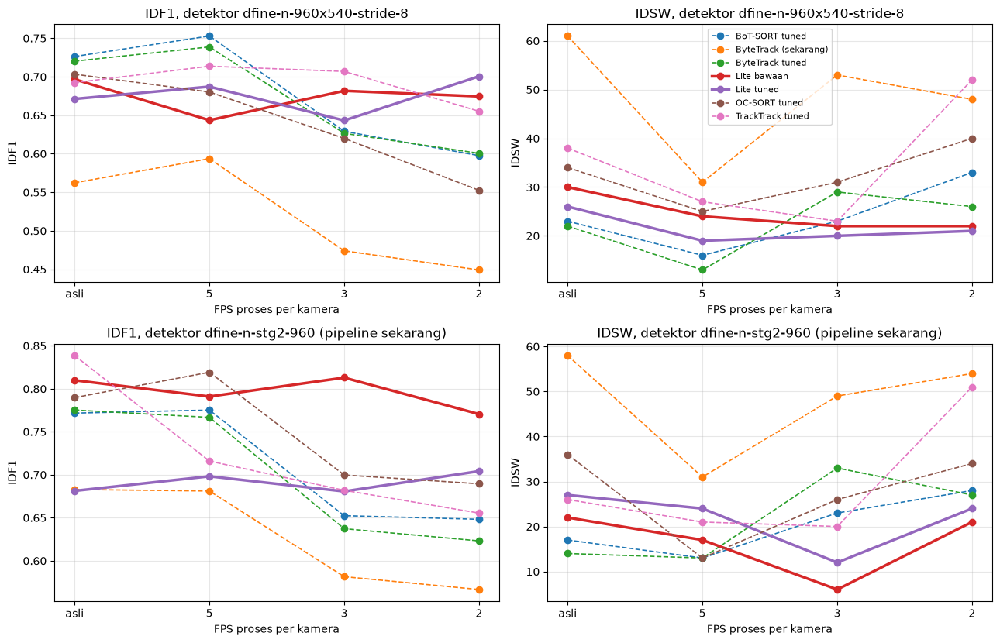

In [8]:
fig, axes = plt.subplots(len(DETECTORS), 2, figsize=(13, 4.2 * len(DETECTORS)), squeeze=False)
xs = [fps_label(f) for f in FPS_LIST]
for row, dname in zip(axes, DETECTORS):
    for metric, a in zip(("IDF1", "IDSW"), row):
        t = fps_table([r for r in ROWS if r["detektor"] == dname], metric, by=("tracker",))
        for name, vals in t.iterrows():
            lite = name.startswith("Lite")
            a.plot(range(len(xs)), [vals[x] for x in xs], marker="o", lw=2.5 if lite else 1.2, ls="-" if lite else "--", label=name)
        a.set_xticks(range(len(xs)), xs); a.set_xlabel("FPS proses per kamera"); a.set_ylabel(metric); a.grid(alpha=0.3)
        a.set_title(f"{metric}, detektor {dname}")
axes[0][1].legend(fontsize=8)
plt.tight_layout()
savefig("idf1_idsw_per_fps")

## 4. Pipeline: semua run di `runs/`

Setiap run di `runs/` dinilai dengan label yang sama. Run yang dibuat `scripts/run_pipeline_lite.py` adalah pipeline hen-detect-ppe yang sama persis, dengan tracker diganti Lite (kode pipeline tidak diubah), jadi perbedaannya murni tracker:

| Run | Isi |
|---|---|
| `hen_<tanggal>_bytetrack` | pembanding: pipeline sekarang (ByteTrack, orang skor 0,5 ke atas) |
| `hen_<tanggal>_lite` | Lite bawaan, orang skor 0,5 ke atas ke tracker (tahap 1 di `docs/INTEGRASI.md`) |
| `hen_<tanggal>_lite-skorrendah` | Lite bawaan, orang skor 0,1 ke atas ke tracker (tahap 3) |

**Frame yang dinilai.** Pipeline mengambil sampel dengan ffmpeg: sampel k pada 3 fps adalah frame 5k + 2 (lihat `config.sampler` di `run.json`). Box pipeline dinilai di frame itu. Untuk klip yang hanya dilabeli tiap 5 frame, box dinilai di frame berlabel terdekat (paling jauh 2 frame).

**Membandingkan dengan adil.** Bandingkan run hanya di klip yang sama, dengan detektor yang sama. Run BE (`be_*`) memakai detektor lain (`8db65e31`, versi letterbox dengan NMS 0,7), jadi selisihnya bukan hanya tracker.

In [9]:
clip_by_name = {c.name: c for c in CLIPS}
run_rows, run_info = [], {}
if RUNS_DIR.exists():
    for rd in sorted(p for p in RUNS_DIR.iterdir() if (p / "run.json").exists()):
        info = gtm.run_info(rd)
        run_info[info["run"]] = info
        for cname in info["clips"]:
            c = clip_by_name.get(cname)
            if c is None or not (rd / cname / "observations.jsonl").exists():
                continue
            seq = SEQS[(MAIN_DET, cname)]
            row = gtm.eval_run(seq, rd, c.fps or 15, clip=c)
            row.update(pipeline=info["pipeline"], fps=info["fps"], run=info["run"], kelompok=kelompok(cname),
                       detektor=f"pipeline {info['detector_sha'][:8]}", sweep=info["sweep"] or "")
            run_rows.append(row)
if run_rows:
    rr = pd.DataFrame([{k: v for k, v in r.items() if k != "raw"} | mot17.mm.summarize(r["raw"]) for r in run_rows])
    print(f"{rr.run.nunique()} run, {len(rr)} pasangan run x klip")
    display(rr[["run", "seq", "fps", "detektor", "IDF1", "HOTA", "MOTA", "IDSW", "FP", "FN", "IDs", "GT_IDs"]]
            .sort_values(["seq", "fps", "run"]).round(3))
    RESULTS["pipeline_runs"] = rr.drop(columns=["raw"], errors="ignore").to_dict("records")
else:
    print("tidak ada output pipeline di", RUNS_DIR)
save_results()

33 run, 59 pasangan run x klip


,run,seq,fps,detektor,IDF1,HOTA,MOTA,IDSW,FP,FN,IDs,GT_IDs
16,hen_20261112_bytetrack,sub_0_te6_0000-0015s,3.0,pipeline 78411143,0.533,0.414,0.293,1,29,151,11,9
30,hen_20261112_lite,sub_0_te6_0000-0015s,3.0,pipeline 78411143,0.602,0.470,0.406,1,14,137,9,9
39,hen_20261112_lite-skorrendah,sub_0_te6_0000-0015s,3.0,pipeline 78411143,0.619,0.482,0.391,1,30,125,9,9
17,hen_20261112_bytetrack,sub_1_te8_0000-0012s,3.0,pipeline 78411143,0.657,0.556,0.457,1,36,63,7,6
31,hen_20261112_lite,sub_1_te8_0000-0012s,3.0,pipeline 78411143,0.717,0.618,0.473,0,36,61,6,6
40,hen_20261112_lite-skorrendah,sub_1_te8_0000-0012s,3.0,pipeline 78411143,0.749,0.659,0.516,0,38,51,6,6
18,hen_20261112_bytetrack,sub_5_te14_0000-0011s,3.0,pipeline 78411143,0.539,0.453,0.296,1,12,56,7,7
32,hen_20261112_lite,sub_5_te14_0000-0011s,3.0,pipeline 78411143,0.638,0.536,0.398,0,13,46,7,7
41,hen_20261112_lite-skorrendah,sub_5_te14_0000-0011s,3.0,pipeline 78411143,0.671,0.562,0.418,0,17,40,7,7
19,hen_20261112_bytetrack,sub_5_te5_0000-0014s,3.0,pipeline 78411143,0.364,0.260,0.253,4,2,68,7,3


### Pipeline + Lite vs pipeline sekarang (detektor sama, klip sama)

Hanya run yang mencakup **semua** klip utama dan bukan bagian dari sweep. Angka digabung per kelompok klip (klien bersih, klien bocor, eksternal) dan untuk semua klip.

In [10]:
base_names = {c.name for c in CLIPS}
full = [r for r in run_info if base_names <= set(run_info[r]["clips"]) and not run_info[r]["sweep"]]
if full:
    sel = [r for r in run_rows if r["run"] in full]
    for r in sel:
        r["tracker"] = r["run"]
    groups = sorted({r["kelompok"] for r in sel}) + ["semua klip"]
    parts = []
    for g in groups:
        rows_g = [r for r in sel if g == "semua klip" or r["kelompok"] == g]
        t = mot17.summary(rows_g, by=("tracker",), sort=None)
        t.insert(0, "kelompok", g)
        parts.append(t.reset_index())
    cmp_runs = pd.concat(parts).set_index(["kelompok", "tracker"])
    display(show(cmp_runs, ["IDF1", "HOTA", "MOTA", "AssA", "DetA", "IDSW", "FP", "FN", "IDs", "GT_IDs"]))
    RESULTS["pipeline_lengkap"] = cmp_runs.reset_index().to_dict("records")
    pc = mot17.summary(sel, by=("seq", "tracker"), sort=None)["IDF1"].unstack("tracker")
    print("IDF1 per klip")
    display(pc.style.format("{:.3f}").background_gradient(cmap="Greens", axis=1))
else:
    print("belum ada run yang mencakup semua klip. Jalankan scripts/run_pipeline_lite.py (lihat docs/INTEGRASI.md).")
save_results()

IDF1 per klip


tracker,hen_20261112_bytetrack,hen_20261112_lite,hen_20261112_lite-skorrendah
seq,,,
sub_0_te6_0000-0015s,0.533,0.602,0.619
sub_1_te8_0000-0012s,0.657,0.717,0.749
sub_5_te14_0000-0011s,0.539,0.638,0.671
sub_5_te5_0000-0014s,0.364,0.449,0.536
sub_7_te6_0000-0012s,0.475,0.643,0.661
v03_momen_026_0000-0103s,1.000,1.000,1.000
v10_momen_004_0000-0080s,0.780,0.778,0.721
v15_momen_015_0000-0091s,0.730,0.762,0.911
v18_momen_002_0000-0035s,0.414,0.830,0.791


### Sweep FPS

Run dengan nama `<nama>_fps<N>` (dan run 3 fps tanpa akhiran, kalau ada) digambar sebagai satu garis per nama. Biasanya hanya di satu klip (v10).

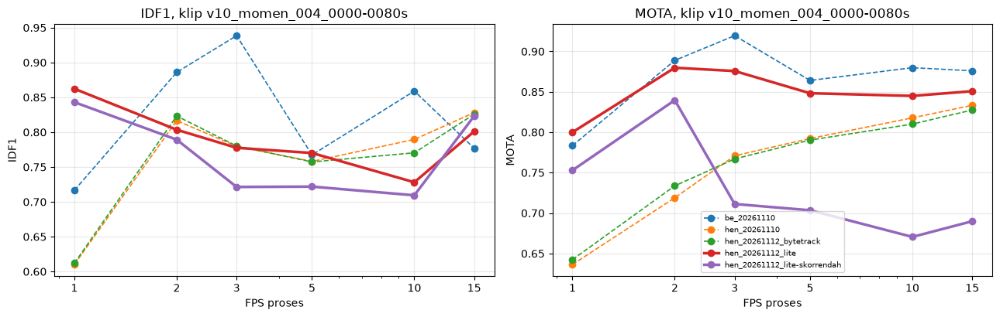

IDF1 (kolom = FPS proses)


fps,1.0,2.0,3.0,5.0,10.0,15.0
tracker,,,,,,
be_20261110,0.717,0.886,0.938,0.767,0.859,0.777
hen_20261110,0.610,0.817,0.780,0.758,0.790,0.828
hen_20261112_bytetrack,0.612,0.823,0.780,0.757,0.770,0.826
hen_20261112_lite,0.862,0.803,0.778,0.770,0.728,0.801
hen_20261112_lite-skorrendah,0.843,0.789,0.721,0.722,0.709,0.823


MOTA (kolom = FPS proses)


fps,1.0,2.0,3.0,5.0,10.0,15.0
tracker,,,,,,
be_20261110,0.783,0.889,0.919,0.864,0.880,0.876
hen_20261110,0.636,0.719,0.771,0.792,0.818,0.833
hen_20261112_bytetrack,0.642,0.734,0.767,0.790,0.810,0.828
hen_20261112_lite,0.800,0.880,0.876,0.848,0.845,0.851
hen_20261112_lite-skorrendah,0.753,0.840,0.711,0.703,0.671,0.690


In [11]:
import re
sw = [r for r in run_rows if r.get("sweep")]
if sw:
    for r in sw:
        r["seri"] = re.sub(r"_fps\d+$", "", r["run"])
    seri = {r["seri"] for r in sw}
    clips_sw = sorted({r["seq"] for r in sw})
    # run 3 fps dengan nama yang sama (tanpa akhiran _fps), hanya di klip sweep
    extra = [dict(r, seri=r["run"]) for r in run_rows if r["run"] in seri and r["seq"] in clips_sw]
    allr = sw + extra
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    sweep_tab = {}
    for metric, a in zip(("IDF1", "MOTA"), axes):
        t = mot17.summary([dict(r, tracker=r["seri"]) for r in allr], by=("tracker", "fps"), sort=None)[metric].unstack("fps")
        sweep_tab[metric] = t
        for name, vals in t.iterrows():
            lite = "lite" in name
            a.plot(vals.index, vals.values, marker="o", lw=2.5 if lite else 1.2, ls="-" if lite else "--", label=name)
        a.set_xlabel("FPS proses"); a.set_ylabel(metric); a.grid(alpha=0.3); a.set_xscale("log")
        a.set_xticks([1, 2, 3, 5, 10, 15], ["1", "2", "3", "5", "10", "15"]); a.set_title(f"{metric}, klip {', '.join(clips_sw)}")
    axes[1].legend(fontsize=7)
    plt.tight_layout()
    savefig("pipeline_sweep_fps")
    for metric, t in sweep_tab.items():
        print(metric, "(kolom = FPS proses)")
        display(t.round(3))
        RESULTS[f"pipeline_sweep_{metric}"] = t.reset_index().to_dict("records")
    save_results()
else:
    print("tidak ada run sweep")

## 5. Detektor sempurna: tracker atau detektor yang salah?

Tracker diberi box label sebagai deteksi, dengan skor tinggi. Sisa kesalahannya murni dari tracker.
- Kalau IDF1 dengan detektor sempurna jauh di atas IDF1 dengan D-FINE, sebagian besar masalah ada di **detektor**.
- Kalau keduanya sama-sama rendah, masalahnya di **tracker** (misalnya orang berpapasan atau tertutup lama).

In [12]:
ORACLE = []
for c in CLIPS:
    s = SEQS[(MAIN_DET, c.name)]
    od = {f: v for f, v in gtm.oracle_dets(c, (s.width, s.height)).items() if f <= s.length}
    ORACLE.append(gtm.to_seq(c, od, "label (sempurna)", OCCLUDED, SMALL))
rows_or = mot17.run_benchmark(SPECS, ORACLE, fps_list=(MAIN_FPS,), progress=prog)
real = mot17.summary([r for r in ROWS if r["detektor"] == MAIN_DET and r["target_fps"] == MAIN_FPS], by=("tracker",), sort=None)
orac = mot17.summary(rows_or, by=("tracker",), sort=None)
cmp_df = pd.DataFrame({"IDF1 dengan D-FINE": real["IDF1"], "IDF1 detektor sempurna": orac["IDF1"],
                       "IDSW dengan D-FINE": real["IDSW"], "IDSW detektor sempurna": orac["IDSW"]})
cmp_df["selisih IDF1 (bagian detektor)"] = cmp_df["IDF1 detektor sempurna"] - cmp_df["IDF1 dengan D-FINE"]
print(f"{MAIN_FPS} FPS, detektor {MAIN_DET}")
display(cmp_df.sort_values("IDF1 dengan D-FINE", ascending=False).style.format("{:.3f}", subset=[c for c in cmp_df.columns if "IDF1" in c]))
RESULTS["oracle"] = cmp_df.reset_index().to_dict("records")
save_results()

  0%|          | 0/63 [00:00<?, ?it/s]

3 FPS, detektor dfine-n-960x540-stride-8


,IDF1 dengan D-FINE,IDF1 detektor sempurna,IDSW dengan D-FINE,IDSW detektor sempurna,selisih IDF1 (bagian detektor)
tracker,,,,,
TrackTrack tuned,0.707,0.901,23,12,0.194
Lite bawaan,0.682,0.956,22,3,0.275
Lite tuned,0.643,0.957,20,3,0.313
BoT-SORT tuned,0.629,0.899,23,14,0.270
ByteTrack tuned,0.627,0.889,29,14,0.262
OC-SORT tuned,0.620,0.917,31,6,0.297
ByteTrack (sekarang),0.474,0.898,53,11,0.424


## 6. Tolok ukur detektor

Bagian ini menilai **detektor saja** (tanpa tracker), dengan aturan yang tetap (`gtm.DET_BENCH_RULES`, versi `gtm.DET_BENCH_VERSION`), supaya detektor baru bisa langsung dibandingkan dengan yang lama:

- Frame berlabel di grid 3 fps, label sudah digeser (bagian 2). IoU 0,5, satu label satu deteksi. Tanpa NMS, sama dengan pipeline hen.
- Orang kecil (di bawah 60 px) dan area abaikan tidak dinilai. Orang tertutup tetap dinilai.
- **recall** = porsi orang yang ditemukan di ambang 0,5 (ambang produksi). **AP50** = kualitas urutan skor di semua ambang. AP50 tinggi tapi recall rendah artinya orangnya ditemukan, tapi skornya di bawah ambang.

**Sebab orang terlewat (FN)**, diambil yang pertama berlaku:

| Sebab | Arti |
|---|---|
| skor rendah | ada deteksi yang pas (IoU 0,5 ke atas) tapi skornya 0,1 sampai di bawah ambang |
| box meleset | ada deteksi di ambang, tapi IoU-nya hanya 0,2 sampai 0,5 |
| tertutup | label ditandai tertutup sebagian |
| kerumunan | box label tertutup orang lain minimal 30% |
| tepi frame | box menyentuh tepi gambar |
| kecil/jauh | tinggi orang di bawah 10% tinggi frame |

**Sebab box salah (FP)**: box dobel (orang yang sama sudah ditemukan), box meleset, objek diam berulang (box di tempat yang sama di 5 frame atau lebih, misalnya rak, tiang, handle hand pallet), latar/lainnya. Nama sebab sama dengan `evaluate.py` di hen-detect-ppe.

Hasil setiap detektor ditambahkan ke `experiments/05_ground_truth/tolok_ukur_detektor.csv`, jadi riwayatnya terkumpul di satu file.

In [13]:
import hashlib
BENCH_FILE = REPO / "experiments" / "05_ground_truth" / "tolok_ukur_detektor.csv"

def sha16(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""):
            h.update(b)
    return h.hexdigest()[:16]

BENCH, BENCH_ERR = [], {}
for dname, dpath in DETECTORS.items():
    sha = sha16(dpath)
    for c in CLIPS:
        row, err = gtm.detector_benchmark(c, DETS[(dname, c.name)], dname)
        row.update(kelompok=kelompok(c.name), detektor_sha=sha, run_id=RUN_ID, geser_label=LABEL_SHIFT.get(c.name, 0))
        BENCH.append(row)
        BENCH_ERR[(dname, c.name)] = err
bench = pd.DataFrame(BENCH)
summ = gtm.benchmark_table(BENCH, by=("kelompok", "detektor"))
allc = gtm.benchmark_table(BENCH, by=("detektor",))
allc.index = pd.MultiIndex.from_tuples([("semua klip", d) for d in allc.index], names=["kelompok", "detektor"])
summ = pd.concat([summ, allc])
cols = ["klip", "orang", "recall", "presisi", "F1", "AP50 (rata-rata klip)", "recall@0.3", "FP"]
print(f"ambang 0,5, tolok ukur versi {gtm.DET_BENCH_VERSION}")
display(summ[cols].style.format({c: "{:.3f}" for c in cols if c not in ("klip", "orang", "FP")})
        .background_gradient(subset=["recall", "AP50 (rata-rata klip)"], cmap="Greens"))
display(bench[["klip", "detektor", "orang", "recall", "presisi", "AP50", "recall@0.3", "FP@0.3"]]
        .set_index(["klip", "detektor"]).round(3))
RESULTS["detektor"] = bench.to_dict("records")

# riwayat: satu baris per (versi aturan, klip, file detektor, versi label)
key = ["versi", "klip", "detektor_sha", "gt_version"]
bench[key] = bench[key].astype(str)
if BENCH_FILE.exists():
    old = pd.read_csv(BENCH_FILE, dtype={k: str for k in key})
    old = old[~old.set_index(key).index.isin(bench.set_index(key).index)]
    hist = pd.concat([old, bench], ignore_index=True)
else:
    hist = bench
hist.to_csv(BENCH_FILE, index=False)
print("riwayat:", BENCH_FILE.relative_to(REPO), f"({hist.detektor_sha.nunique()} detektor)")
save_results()

ambang 0,5, tolok ukur versi 1


,,orang,recall,presisi,AP50,recall@0.3,FP@0.3
klip,detektor,,,,,,
sub_0_te6_0000-0015s,dfine-n-960x540-stride-8,257,0.720,0.853,0.761,0.747,104
sub_1_te8_0000-0012s,dfine-n-960x540-stride-8,184,0.554,0.703,0.579,0.598,115
sub_5_te14_0000-0011s,dfine-n-960x540-stride-8,97,0.474,0.613,0.524,0.557,48
sub_5_te5_0000-0014s,dfine-n-960x540-stride-8,107,0.467,0.510,0.537,0.589,102
sub_7_te6_0000-0012s,dfine-n-960x540-stride-8,71,0.592,0.667,0.649,0.690,84
v03_momen_026_0000-0103s,dfine-n-960x540-stride-8,296,0.240,0.986,0.994,1.000,5
v10_momen_004_0000-0080s,dfine-n-960x540-stride-8,516,0.957,0.910,0.970,0.979,274
v15_momen_015_0000-0091s,dfine-n-960x540-stride-8,716,0.638,0.976,0.913,0.767,64
v18_momen_002_0000-0035s,dfine-n-960x540-stride-8,368,0.965,0.903,0.978,0.973,136


riwayat: experiments/05_ground_truth/tolok_ukur_detektor.csv (2 detektor)


Orang terlewat dan box salah, per sebab (jumlah, ambang 0,5). Grafik kanan: recall saat ambang skor diturunkan.

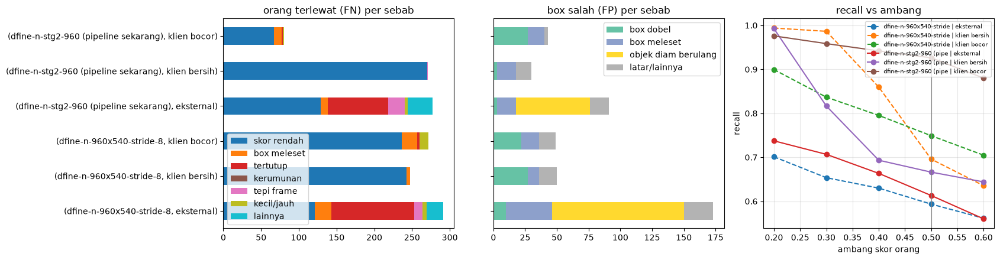

In [14]:
fn_cols = [f"FN {x}" for x in gtm.FN_ORDER]
fp_cols = [f"FP {x}" for x in gtm.FP_ORDER]
by_g = gtm.benchmark_table(BENCH, by=("detektor", "kelompok"))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
by_g[fn_cols].rename(columns=lambda x: x[3:]).plot.barh(stacked=True, ax=axes[0], colormap="tab10")
axes[0].set_title("orang terlewat (FN) per sebab"); axes[0].set_ylabel("")
by_g[fp_cols].rename(columns=lambda x: x[3:]).plot.barh(stacked=True, ax=axes[1], colormap="Set2")
axes[1].set_title("box salah (FP) per sebab"); axes[1].set_ylabel(""); axes[1].set_yticklabels([])
ths = [0.2, 0.3, 0.4, 0.5, 0.6]
for (d, g), r in by_g.iterrows():
    axes[2].plot(ths, [r[f"recall@{t:g}"] for t in ths], marker="o", label=f"{d[:22]} | {g}",
                 ls="-" if "stg2" in d else "--")
axes[2].axvline(0.5, color="gray", lw=0.8); axes[2].set_xlabel("ambang skor orang"); axes[2].set_ylabel("recall")
axes[2].grid(alpha=0.3); axes[2].legend(fontsize=7); axes[2].set_title("recall vs ambang")
plt.tight_layout()
savefig("detektor_sebab")

Contoh kesalahan detektor utama: potongan gambar per sebab (kotak hijau = label, merah = deteksi salah, kuning = deteksi skor rendah).

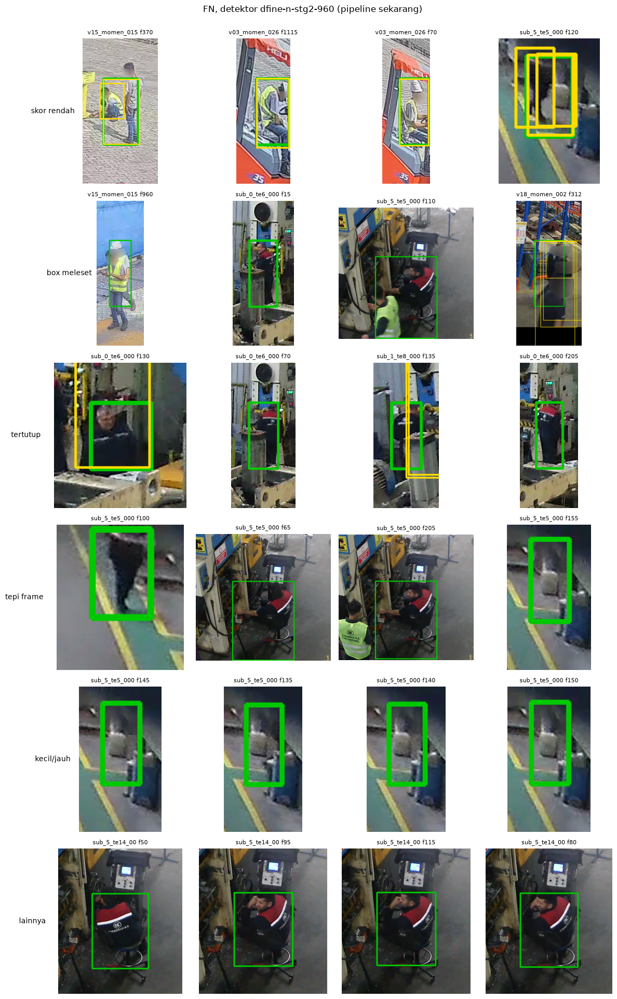

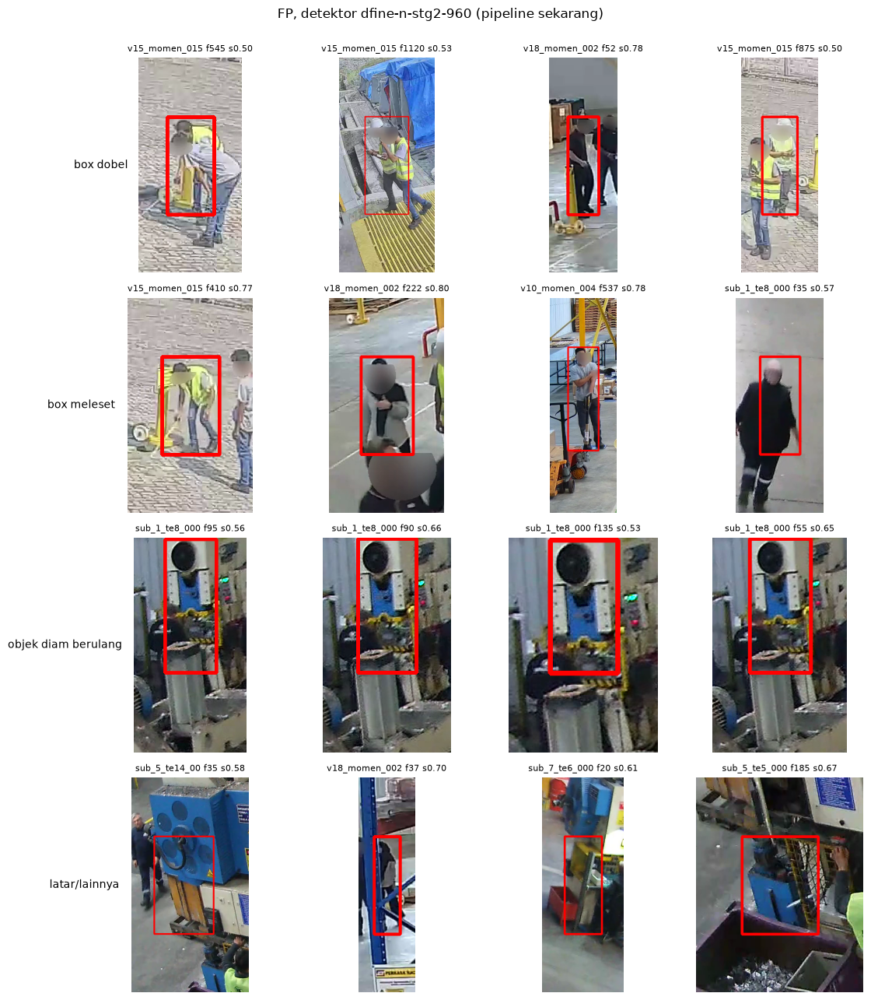

In [15]:
import cv2

def frame_at(video, f):
    cap = cv2.VideoCapture(str(video)); cap.set(cv2.CAP_PROP_POS_FRAMES, int(f))
    ok, img = cap.read(); cap.release()
    return img if ok else None

def crop_box(img, b, pad=0.6):
    x1, y1, x2, y2 = b; w, h = x2 - x1, y2 - y1
    X1, Y1 = int(max(0, x1 - pad * w)), int(max(0, y1 - pad * h))
    X2, Y2 = int(min(img.shape[1], x2 + pad * w)), int(min(img.shape[0], y2 + pad * h))
    return img[Y1:Y2, X1:X2], (X1, Y1)

GALLERY_DET = next((d for d in DETECTORS if "stg2" in d), MAIN_DET)
N_PER = 4
for kind, order in (("FN", gtm.FN_ORDER), ("FP", gtm.FP_ORDER)):
    errs = pd.concat([BENCH_ERR[(GALLERY_DET, c.name)] for c in CLIPS if len(BENCH_ERR[(GALLERY_DET, c.name)])])
    errs = errs[errs.kind == kind]
    causes = [x for x in order if (errs.sebab == x).any()]
    if not causes:
        continue
    fig, axes = plt.subplots(len(causes), N_PER, figsize=(3 * N_PER, 3.2 * len(causes)), squeeze=False)
    for ax_row, cause in zip(axes, causes):
        ex = errs[errs.sebab == cause].sample(min(N_PER, (errs.sebab == cause).sum()), random_state=0)
        for a in ax_row:
            a.axis("off")
        for a, (_, e) in zip(ax_row, ex.iterrows()):
            c = clip_by_name[e.klip]
            img = frame_at(c.video, e.frame)
            if img is None:
                continue
            b = [int(v) for v in e.box]
            color = (0, 200, 0) if kind == "FN" else (0, 0, 255)
            cv2.rectangle(img, (b[0], b[1]), (b[2], b[3]), color, max(2, img.shape[1] // 600))
            d = DETS[(GALLERY_DET, e.klip)].get(int(e.frame) + 1)
            if kind == "FN" and d is not None:
                for x in d[(d[:, 4] >= 0.1) & (d[:, 4] < 0.5)]:
                    if gtm._ioa_xyxy(np.array([b], float), x[None, :4]).max() > 0.3:
                        cv2.rectangle(img, (int(x[0]), int(x[1])), (int(x[2]), int(x[3])), (0, 220, 255), max(1, img.shape[1] // 900))
            cr, _ = crop_box(img, b)
            a.imshow(cv2.cvtColor(cr, cv2.COLOR_BGR2RGB))
            a.set_title(f"{e.klip[:13]} f{e.frame}" + (f" s{e.skor:.2f}" if e.skor == e.skor else ""), fontsize=8)
        ax_row[0].text(-0.1, 0.5, cause, transform=ax_row[0].transAxes, ha="right", va="center", fontsize=10)
    plt.suptitle(f"{kind}, detektor {GALLERY_DET}", y=1.0)
    plt.tight_layout()
    savefig(f"galeri_{kind}")

## 7. Per klip, dan ketahanan terhadap blur dan re-encode
Klip dengan IDF1 rendah adalah tempat terbaik untuk mencari pola kesalahan (lihat videonya di bagian 9).

In [17]:
main_rows = [r for r in ROWS if r["detektor"] == MAIN_DET and r["target_fps"] == MAIN_FPS]
per_clip = mot17.summary(main_rows, by=("seq", "tracker"), sort=None)
pv = per_clip[["IDF1", "IDSW", "IDs", "GT_IDs"]].unstack("tracker")
print(f"{MAIN_FPS} FPS, detektor {MAIN_DET}")
display(pv["IDF1"].style.format("{:.3f}").background_gradient(cmap="Greens", axis=1))
display(pv["IDSW"])
RESULTS["per_clip"] = per_clip.reset_index().to_dict("records")

if VARIANTS:
    vs = [gtm.to_seq(c, DETS[(MAIN_DET, c.name)], MAIN_DET, OCCLUDED, SMALL) for c in VARIANTS]
    keep = {k: SPECS[k] for k in ("Lite tuned", "ByteTrack (sekarang)") if k in SPECS}
    vrows = mot17.run_benchmark(keep, vs, fps_list=(MAIN_FPS,))
    base_names = {c.name.rsplit("_", 1)[0] for c in VARIANTS}
    brows = [dict(r, varian="asli") for r in main_rows if r["seq"] in base_names and r["tracker"] in keep]
    vrows = [dict(r, varian=r["seq"].rsplit("_", 1)[1]) for r in vrows]
    vt = mot17.summary(brows + vrows, by=("varian", "tracker"), sort=None)[["IDF1", "HOTA", "IDSW", "DetA"]].unstack("varian")
    print("Ketahanan: klip yang sama, video asli vs wajah diblur vs di-encode ulang")
    display(vt.style.format("{:.3f}"))
    RESULTS["variants"] = vt.reset_index().to_dict("records")
def json_safe(obj):
    if isinstance(obj, dict):
        return {
            key if isinstance(key, (str, int, float, bool)) or key is None else str(key): json_safe(value)
            for key, value in obj.items()
        }
    if isinstance(obj, (list, tuple)):
        return [json_safe(value) for value in obj]
    return obj

RESULTS = json_safe(RESULTS)
save_results()

3 FPS, detektor dfine-n-960x540-stride-8


tracker,BoT-SORT tuned,ByteTrack (sekarang),ByteTrack tuned,Lite bawaan,Lite tuned,OC-SORT tuned,TrackTrack tuned
seq,,,,,,,
sub_0_te6_0000-0015s,0.648,0.574,0.606,0.543,0.598,0.500,0.600
sub_1_te8_0000-0012s,0.682,0.631,0.702,0.613,0.624,0.602,0.595
sub_5_te14_0000-0011s,0.553,0.513,0.544,0.555,0.545,0.524,0.480
sub_5_te5_0000-0014s,0.273,0.263,0.273,0.462,0.261,0.272,0.541
sub_7_te6_0000-0012s,0.523,0.380,0.523,0.457,0.448,0.359,0.504
v03_momen_026_0000-0103s,0.976,0.196,0.976,0.992,0.992,0.997,0.985
v10_momen_004_0000-0080s,0.000,0.000,0.000,0.000,0.000,0.000,0.000
v15_momen_015_0000-0091s,0.511,0.511,0.513,0.653,0.580,0.600,0.717
v18_momen_002_0000-0035s,0.634,0.492,0.632,0.736,0.666,0.625,0.725


tracker,BoT-SORT tuned,ByteTrack (sekarang),ByteTrack tuned,Lite bawaan,Lite tuned,OC-SORT tuned,TrackTrack tuned
seq,,,,,,,
sub_0_te6_0000-0015s,0,0,0,0,0,0,0
sub_1_te8_0000-0012s,0,1,0,0,0,1,2
sub_5_te14_0000-0011s,1,1,1,0,0,2,1
sub_5_te5_0000-0014s,2,3,2,4,3,4,3
sub_7_te6_0000-0012s,1,2,1,1,1,1,2
v03_momen_026_0000-0103s,0,3,0,0,0,0,0
v10_momen_004_0000-0080s,0,0,0,0,0,0,0
v15_momen_015_0000-0091s,5,9,6,7,10,6,7
v18_momen_002_0000-0035s,14,34,19,10,6,17,8


Ketahanan: klip yang sama, video asli vs wajah diblur vs di-encode ulang


## 8. Validasi silang ambang Lite

Ambang Lite tuned disetel terhadap tracker referensi (notebook 02). Di sini ambang disetel langsung terhadap label manusia, dengan cara yang jujur: klip dibagi dua, parameter dipilih di satu bagian lalu dinilai di bagian lain, dan sebaliknya. ByteTrack diperlakukan sama.

In [18]:
RUN_CV = len(CLIPS) >= 4
SCORE_PAIRS = [(0.4, 0.45), (0.5, 0.55), (0.6, 0.65)]
cv_rows, cv_pick = [], []
if RUN_CV:
    seqs = [SEQS[(MAIN_DET, c.name)] for c in CLIPS]
    names = [s.name for s in seqs]
    folds = [names[0::2], names[1::2]]
    lite_base = SPECS.get("Lite tuned", LITE_DEFAULT)
    grids = {
        "Lite (disetel di ground truth)": [(f"YAKIN {h}, baru {n}, IoU {i}", lite_base.with_params(high_thresh=h, new_thresh=n, min_iou=i))
                                           for h, n in SCORE_PAIRS for i in (0.15, 0.3)],
        "ByteTrack (disetel di ground truth)": [(f"YAKIN {h}, baru {n}, match {m}", PRESETS["ByteTrack"].with_params(
                                                track_high_thresh=h, new_track_thresh=n, match_thresh=m))
                                                for h, n in SCORE_PAIRS for m in (0.8, 0.9)],
    }
    for fam, grid in grids.items():
        for train, test in ((folds[0], folds[1]), (folds[1], folds[0])):
            tr = [s for s in seqs if s.name in train]
            te = [s for s in seqs if s.name in test]
            scores = []
            for label, spec in prog(grid):
                r = mot17.run_benchmark({label: spec}, tr, fps_list=(MAIN_FPS,))
                scores.append((mot17.summary(r, by=("tracker",), sort=None)["IDF1"].iloc[0], label, spec))
            best = max(scores, key=lambda x: x[0])
            cv_pick.append({"tracker": fam, "dipilih di": ", ".join(train), "parameter": best[1], "IDF1 saat memilih": best[0]})
            cv_rows += mot17.run_benchmark({fam: best[2]}, te, fps_list=(MAIN_FPS,))
    display(pd.DataFrame(cv_pick))
    print(f"{MAIN_FPS} FPS, detektor {MAIN_DET}, setiap klip dinilai dengan parameter yang dipilih di klip lain")
    display(show(mot17.summary(main_rows + cv_rows, by=("tracker",))))
    RESULTS["cv"] = cv_pick
    save_results()
else:
    print(f"hanya {len(CLIPS)} klip, validasi silang butuh minimal 4. Dilewati.")

  0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/6 [00:00<?, ?it/s]

,tracker,dipilih di,parameter,IDF1 saat memilih
0,Lite (disetel di ground truth),"sub_0_te6_0000-0015s, sub_5_te14_0000-0011s, s...","YAKIN 0.4, baru 0.45, IoU 0.15",0.687620
1,Lite (disetel di ground truth),"sub_1_te8_0000-0012s, sub_5_te5_0000-0014s, v0...","YAKIN 0.6, baru 0.65, IoU 0.15",0.687334
2,ByteTrack (disetel di ground truth),"sub_0_te6_0000-0015s, sub_5_te14_0000-0011s, s...","YAKIN 0.5, baru 0.55, match 0.9",0.564103
3,ByteTrack (disetel di ground truth),"sub_1_te8_0000-0012s, sub_5_te5_0000-0014s, v0...","YAKIN 0.6, baru 0.65, match 0.9",0.646643


3 FPS, detektor dfine-n-960x540-stride-8, setiap klip dinilai dengan parameter yang dipilih di klip lain


,HOTA,IDF1,MOTA,AssA,DetA,IDSW,IDs,GT_IDs
tracker,,,,,,,,
TrackTrack tuned,0.602,0.707,0.620,0.642,0.566,23,66,37
Lite bawaan,0.590,0.682,0.580,0.642,0.544,22,52,37
Lite (disetel di ground truth),0.573,0.666,0.635,0.578,0.571,20,52,37
Lite tuned,0.556,0.643,0.594,0.565,0.550,20,53,37
BoT-SORT tuned,0.537,0.629,0.636,0.527,0.549,23,47,37
OC-SORT tuned,0.533,0.620,0.550,0.555,0.516,31,63,37
ByteTrack tuned,0.517,0.627,0.615,0.512,0.524,29,47,37
ByteTrack (disetel di ground truth),0.514,0.607,0.600,0.506,0.525,26,50,37
ByteTrack (sekarang),0.388,0.474,0.440,0.371,0.406,53,78,37


## 9. Video perbandingan dengan tanda ID switch

Satu klip dirender jadi grid: video asli, label manusia, lalu satu panel per tracker. Box bertepi **merah tebal "SWITCH"** = ID switch: orang yang sama menurut label tiba-tiba memegang ID tracker lain.

  0%|          | 0/3 [00:00<?, ?it/s]

video: experiments/05_ground_truth/20261112_1422/videos/v10_momen_004_0000-0080s_3fps.mp4 (6.3 MB)


,IDF1,HOTA,MOTA,IDSW,IDSW di video,ID dibuat,GT_IDs
tracker,,,,,,,
Lite tuned,0.0,0.0,0.0,0,0,14,0
ByteTrack (sekarang),0.0,0.0,0.0,0,0,19,0
ByteTrack tuned,0.0,0.0,0.0,0,0,13,0


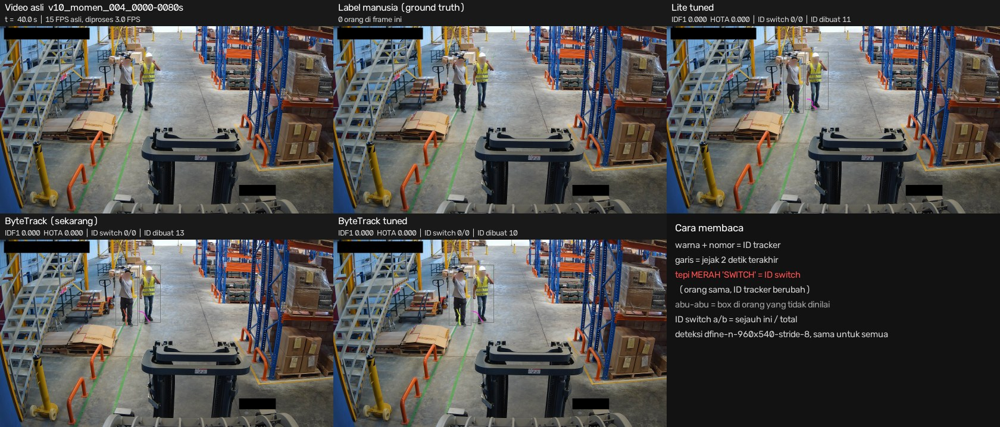

In [19]:
from IPython.display import Image as IPImage, Video

VIDEO_CLIP = per_clip["IDF1"].groupby("seq").mean().idxmin()   # klip tersulit. Ganti dengan nama klip lain kalau mau
VIDEO_FPS = MAIN_FPS
VIDEO_SPECS = {k: SPECS[k] for k in SPECS if k in ("Lite tuned", "ByteTrack (sekarang)", "ByteTrack tuned")}
EMBED = True

seq = SEQS[(MAIN_DET, VIDEO_CLIP)]
clip = clip_by_name[VIDEO_CLIP]
vid = mot17_video.render_comparison(seq, clip.video, VIDEO_SPECS, OUT / "videos" / f"{VIDEO_CLIP}_{VIDEO_FPS}fps.mp4",
                                    target_fps=VIDEO_FPS, panel_width=560, show_gt=True, max_sec=MAX_SEC, progress=prog)
print("video:", vid["video"].relative_to(REPO), f"({vid['video'].stat().st_size / 1e6:.1f} MB)")
display(pd.DataFrame(vid["table"]).set_index("tracker"))
display(IPImage(filename=str(vid["snapshot"]), width=1100))
if EMBED and vid["video"].stat().st_size < 80e6:
    display(Video(str(vid["video"]), embed=True, width=1100, html_attributes="controls loop"))

## 10. Simpan hasil

In [20]:
flat = pd.DataFrame([{k: v for k, v in r.items() if k != "raw"} | mot17.mm.summarize(r["raw"]) for r in ROWS + run_rows + cv_rows])
bench.to_csv(OUT / "tolok_ukur_detektor.csv", index=False)
flat.to_csv(OUT / "per_klip_per_fps.csv", index=False)
save_results()
print("tersimpan:")
for p in sorted(OUT.rglob("*")):
    if p.is_file():
        print("  ", p.relative_to(REPO))

tersimpan:
   experiments/05_ground_truth/20261112_1422/figures/detektor_sebab.png
   experiments/05_ground_truth/20261112_1422/figures/galeri_FN.png
   experiments/05_ground_truth/20261112_1422/figures/galeri_FP.png
   experiments/05_ground_truth/20261112_1422/figures/idf1_idsw_per_fps.png
   experiments/05_ground_truth/20261112_1422/figures/label_sub_0_te6_0000-0015s.png
   experiments/05_ground_truth/20261112_1422/figures/label_sub_1_te8_0000-0012s.png
   experiments/05_ground_truth/20261112_1422/figures/label_sub_5_te14_0000-0011s.png
   experiments/05_ground_truth/20261112_1422/figures/label_sub_5_te5_0000-0014s.png
   experiments/05_ground_truth/20261112_1422/figures/label_sub_7_te6_0000-0012s.png
   experiments/05_ground_truth/20261112_1422/figures/label_v03_momen_026_0000-0103s.png
   experiments/05_ground_truth/20261112_1422/figures/label_v10_momen_004_0000-0080s.png
   experiments/05_ground_truth/20261112_1422/figures/label_v15_momen_015_0000-0091s.png
   experiments/05_groun

## Cara menarik kesimpulan

1. **Pipeline + Lite vs pipeline sekarang** (bagian 4, tabel run lengkap): pipeline yang sama, detektor sama, frame sama, hanya tracker yang beda. Ini angka utama untuk keputusan memasang Lite. Lihat per kelompok: klip bersih lebih jujur daripada klip bocor.
2. **Lite vs ByteTrack di semua FPS** (bagian 3 dan sweep di bagian 4). Lihat apakah keunggulan Lite membesar saat FPS turun.
3. **Apakah tuning notebook 02 berlaku di label manusia?** Bandingkan Lite tuned dengan Lite bawaan, dan dengan hasil validasi silang (bagian 8).
4. **Bagian tracker vs detektor** (bagian 5 dan 6): kalau selisihnya besar, perbaikan berikutnya sebaiknya di detektor atau ambang skornya. Tolok ukur detektor (bagian 6) memberi tahu sebabnya: skor rendah (ambang), box meleset, tertutup, atau objek diam.
5. **Pola kesalahan** (bagian 7 dan 9): klip mana yang sulit, dan apakah blur atau re-encode memengaruhi.

Catatan: hasil hanya sebaik labelnya. Kalau bagian 1 atau cek pergeseran memberi peringatan, perbaiki label dulu.